# 14 · Table 2 and further checks: one scale, rectification, re-acquisition, ink spread, MDC interval

This notebook computes the paper's Table 2 and checks several points of the method on the existing data.
No new photos are used.

| § | Question | Answer in this notebook |
|---|---|---|
| 1 | How do captures outside the capture conditions compare, and which does the app accept? | Table 2 recomputed with **one scale for every row**, **all 45 frames**, frontal row from the **same session**, plus the app's own accept/reject decision |
| 2 | Would rectifying the photo from the four corners help? | The ten Table 3 photos rectified from their four corners and measured with the same pipeline |
| 3 | SD = 0 at ET2: were the ten captures separate photos? | Label position, size and angle in each of the ten photos, and time between them |
| 4 | What causes the bias at ET1? How wide are the printed bars? Is 50 mm / 797 px the right scale? | Barcode-bar fit: ink spread and an independent scale check of 50 mm / 797 px |
| 5 | How certain is the MDC? | χ² interval of the pooled SD |
| 6 | How often does the label identifier decode? | Decode rate on every capture |\n| 7 | What are the per-row pixel counts? | Every scan line of the Table 3 photos, in pixels |

Table numbers follow the paper: Table 2 = sensitivity to capture pose, Table 3 = repeatability and inspectors
(called "Table 1" in notebook 05 and in the file names).

| | |
|---|---|
| **Inputs** | `data/raw/images/` (Table 3 photos), `data/raw/robustness/` (45 sensitivity photos), `results/tables/table2_original_per_capture.csv` (per-capture bottom-edge length and bar widths in px), `results/tables/robustness_per_capture.csv` (notebook 06: barcode scale, decode, app decision), `results/tables/table1.csv` (notebook 05) |
| **Outputs** | `results/tables/table2_one_scale.csv`, `rectification_baseline.csv`, `table3_reacquisition.csv`, `table3_per_row_counts.csv`; `results/figures/table2_one_scale.png`, `rectification_baseline.png`, `table3_reacquisition.png`, `ink_spread.png` |
| **Runtime** | ~1 min |

In [ ]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

import visioncrack as vc
from visioncrack import field
from visioncrack.barcode import encode
from visioncrack.constants import BARCODE_CLASS_MM

FIG = vc.io.results_dir('figures'); TAB = vc.io.results_dir('tables')
GT = np.array(vc.ET_GT_MM)
pd.set_option('display.width', 200)
plt.rcParams.update({'font.size': 11})

## 1 · Table 2 with one scale definition and every frame

Every row uses **one** scale, all **45** frames are kept, and the frontal row is the four frontal photos **taken in the same
session** as the perturbed ones.

Two scale definitions are shown, each applied to every row:

* **bottom edge**: 50 mm / imaged length of the label's bottom edge;
* **barcode**: the scale fitted to the 18 barcode bars of the same photo (notebook 06).

The bar widths in pixels and the bottom-edge length per capture are read from `table2_original_per_capture.csv`,
so the two versions differ only in the scale.

**Folder names.** `roll` holds photos rotated ≈ 15° **in the image plane**, so the row is labelled *in-plane rotation*.

In [ ]:
t2 = pd.read_csv(TAB / 'table2_original_per_capture.csv')
sw = pd.read_csv(TAB / 'robustness_per_capture.csv')[['file', 'scale', 'decode_ok', 'app_result']]
t2 = t2.merge(sw, on='file', validate='one_to_one')
assert len(t2) == 45 and t2.scale.notna().all()

PX = t2[[f'ET{k}_px' for k in range(1, 6)]].to_numpy()
scales = {'bottom edge': 50.0 / t2.bottom_edge_px.to_numpy(), 'barcode': t2.scale.to_numpy()}
ORDER = ['norm', 'dist', 'yaw', 'pitch', 'roll']
NAME = {'norm': 'Frontal (same session)', 'dist': 'Distance', 'yaw': 'Yaw', 'pitch': 'Pitch',
        'roll': 'In-plane rotation ≈ 15°'}

rows = []
for c in ORDER:
    m = (t2.folder == c).to_numpy()
    r = dict(condition=NAME[c], n=int(m.sum()), accepted_by_app=f"{(t2.app_result[m] == 'accepted').sum()}/{m.sum()}")
    for sname, s in scales.items():
        W = PX[m] * s[m, None]
        r[f'SD_pooled [{sname}]'] = np.sqrt((W.std(0, ddof=1) ** 2).mean())
        r[f'MAE [{sname}]'] = np.abs(W - GT).mean()
        r[f'scale_CV_% [{sname}]'] = 100 * s[m].std(ddof=1) / s[m].mean()
    rows.append(r)
T2 = pd.DataFrame(rows).set_index('condition')
T2.to_csv(TAB / 'table2_one_scale.csv', float_format='%.4f')
T2.round(3)

,n,accepted_by_app,SD_pooled [bottom edge],MAE [bottom edge],scale_CV_% [bottom edge],SD_pooled [barcode],MAE [barcode],scale_CV_% [barcode]
condition,,,,,,,,
Frontal (same session),4,4/4,0.005,0.144,0.258,0.002,0.095,0.058
Distance,6,0/6,0.019,0.204,0.350,0.014,0.102,0.786
Yaw,12,0/12,0.092,0.081,1.897,0.190,0.247,9.422
Pitch,11,2/11,0.572,0.494,8.956,0.339,0.303,2.216
In-plane rotation ≈ 15°,12,0/12,0.526,0.552,20.450,0.036,0.056,3.032


In [ ]:
sd_e, sd_b = T2['SD_pooled [bottom edge]'], T2['SD_pooled [barcode]']
# frontal has the smallest spread under either scale
assert sd_e.idxmin() == sd_b.idxmin() == NAME['norm']
# the app rejects 39 of the 41 perturbed frames
pert = t2[t2.folder != 'norm']
assert (pert.app_result != 'accepted').sum() == 39 and len(pert) == 41
ratio_e = (sd_e.drop(NAME['norm']) / sd_e[NAME['norm']])
ratio_b = (sd_b.drop(NAME['norm']) / sd_b[NAME['norm']])
print('spread of perturbed rows / frontal spread, bottom-edge scale:', ratio_e.round(0).to_dict())
print('spread of perturbed rows / frontal spread, barcode scale    :', ratio_b.round(0).to_dict())
print('first condition that rejects each perturbed frame:', pert.app_result.value_counts().to_dict())

spread of perturbed rows / frontal spread, bottom-edge scale: {'Distance': 4.0, 'Yaw': 18.0, 'Pitch': 112.0, 'In-plane rotation ≈ 15°': 103.0}
spread of perturbed rows / frontal spread, barcode scale    : {'Distance': 6.0, 'Yaw': 89.0, 'Pitch': 158.0, 'In-plane rotation ≈ 15°': 17.0}
first condition that rejects each perturbed frame: {'coverage': 33, 'corners': 6, 'accepted': 2}


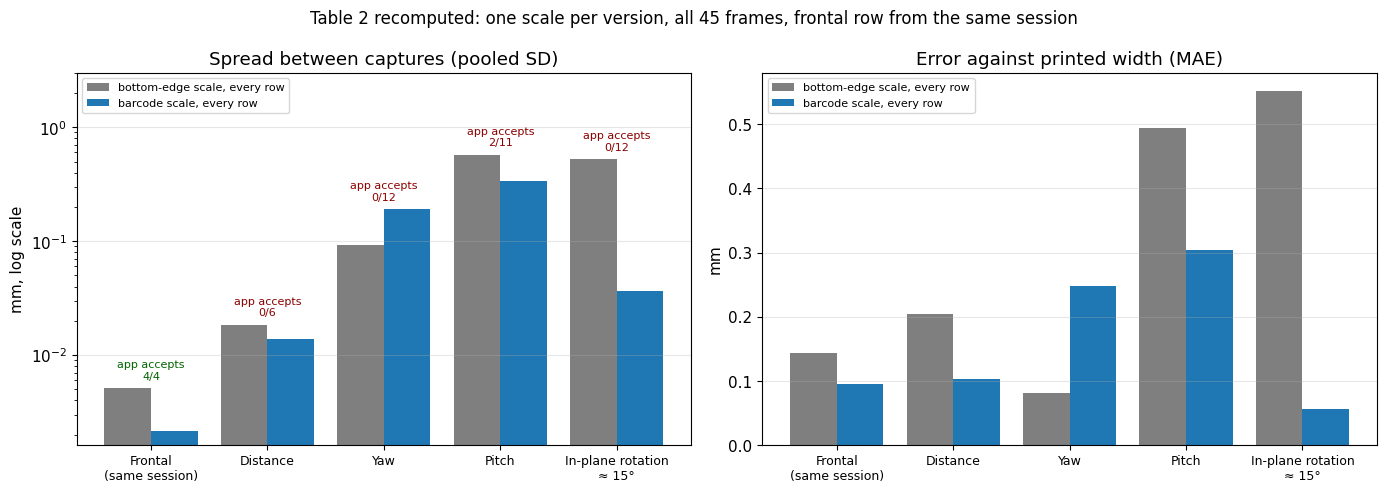

In [ ]:
x = np.arange(len(T2)); lab = [NAME[c].replace(' (same session)', '\n(same session)').replace(' ≈', '\n≈') for c in ORDER]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for a, key, ttl in [(a1, 'SD_pooled', 'Spread between captures (pooled SD)'), (a2, 'MAE', 'Error against printed width (MAE)')]:
    a.bar(x - .2, T2[f'{key} [bottom edge]'], .4, color='tab:gray', label='bottom-edge scale, every row')
    a.bar(x + .2, T2[f'{key} [barcode]'], .4, color='tab:blue', label='barcode scale, every row')
    a.set_xticks(x, lab, fontsize=9); a.set_title(ttl); a.set_ylabel('mm'); a.grid(alpha=.3, axis='y')
for i, acc in enumerate(T2.accepted_by_app):
    a1.text(i, 1.15 * max(T2.iloc[i]['SD_pooled [bottom edge]'], T2.iloc[i]['SD_pooled [barcode]']), f'app accepts\n{acc}',
            ha='center', va='bottom', fontsize=8, color='darkgreen' if acc.split('/')[0] == acc.split('/')[1] else 'darkred')
a1.set_yscale('log'); a1.set_ylim(top=3); a1.set_ylabel('mm, log scale'); a1.legend(fontsize=8, loc='upper left'); a2.legend(fontsize=8)
fig.suptitle('Table 2 recomputed: one scale per version, all 45 frames, frontal row from the same session', fontsize=12)
plt.tight_layout(); plt.savefig(FIG / 'table2_one_scale.png', dpi=150); plt.show()

**Reading.** Under either scale the frontal captures, the only ones the app accepts, have the smallest spread between captures.
The ranking by MAE changes with the scale definition, so the comparison between rows should rest on spread and on what the app
rejects, not on MAE.

## 2 · Rectification baseline (homography from the four corners)

Each of the ten Table 3 photos is warped with the homography that maps its four detected label corners to the ROI rectangle, then
measured with the identical width pipeline. Without rectification is the published pipeline.

In [ ]:
caps, _ = vc.load_table1()
roi = vc.preview_roi(image_wh=(2160, 3840), screen_wh=(430, 932))
full = np.array([[0, 0], [roi.w - 1, 0], [0, roi.h - 1], [roi.w - 1, roi.h - 1]])
base, rect = [], []
for path, bbox in zip(caps.path, caps.bbox):
    rgb = vc.read_rgb(path)
    base.append(vc.measure_capture(rgb, bbox, roi).widths_mm)
    src = (np.asarray(bbox, float) + [roi.x, roi.y]).astype(np.float32)
    dst = (full + [roi.x, roi.y]).astype(np.float32)
    H = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(rgb, H, (rgb.shape[1], rgb.shape[0]), flags=cv2.INTER_LINEAR, borderValue=(255, 255, 255))
    rect.append(vc.measure_capture(warped, full, roi).widths_mm)
base, rect = np.array(base).round(3), np.array(rect).round(3)

def summary(a):
    return pd.Series({**{f'SD ET{k+1}': a[:, k].std(ddof=1) for k in range(5)},
                      'pooled SD': np.sqrt((a.std(0, ddof=1) ** 2).mean()), 'MAE': np.abs(a.mean(0) - GT).mean()})
RB = pd.DataFrame({'without rectification (published)': summary(base), 'homography-rectified': summary(rect)}).T
RB.to_csv(TAB / 'rectification_baseline.csv', float_format='%.4f')
assert round(RB.iloc[0]['pooled SD'], 3) == 0.011 and round(RB.iloc[1]['pooled SD'], 3) == 0.024
assert round(RB.iloc[0]['MAE'], 3) == 0.061 and round(RB.iloc[1]['MAE'], 3) == 0.075
RB.round(4)

,SD ET1,SD ET2,SD ET3,SD ET4,SD ET5,pooled SD,MAE
without rectification (published),0.0057,0.0000,0.0133,0.0140,0.0126,0.0106,0.0607
homography-rectified,0.0089,0.0126,0.0309,0.0293,0.0278,0.0238,0.0752


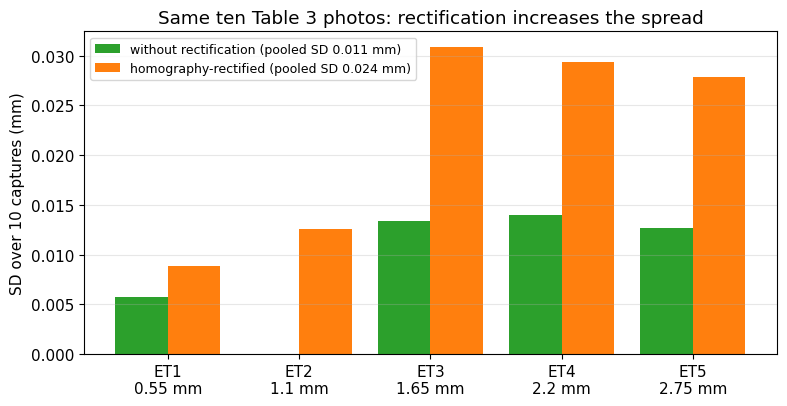

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.2)); x = np.arange(5)
ax.bar(x - .2, RB.iloc[0, :5], .4, color='tab:green', label=f"without rectification (pooled SD {RB.iloc[0]['pooled SD']:.3f} mm)")
ax.bar(x + .2, RB.iloc[1, :5], .4, color='tab:orange', label=f"homography-rectified (pooled SD {RB.iloc[1]['pooled SD']:.3f} mm)")
ax.set_xticks(x, [f'ET{k+1}\n{g} mm' for k, g in enumerate(GT)]); ax.set_ylabel('SD over 10 captures (mm)')
ax.set_title('Same ten Table 3 photos: rectification increases the spread'); ax.legend(fontsize=9); ax.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.savefig(FIG / 'rectification_baseline.png', dpi=150); plt.show()

## 3 · Were the ten Table 3 captures separate acquisitions?

This section shows the photos are not one frame processed ten times: the label sits at a different place, size and angle in
each. Why ET2 still gives SD = 0 is shown with the per-row counts in §7.

In [ ]:
rows, imgs = [], []
for p in caps.path:
    img = vc.read_rgb(p); imgs.append(img)
    (cx, cy), (w, h), _ = field.find_red_label(img)
    r = field.measure_field(p)
    rows.append(dict(photo=p.name, t_s=int(p.stem), label_cx_px=cx, label_cy_px=cy, label_width_px=max(w, h),
                     angle_deg=r.angle_deg, code=r.code, scale_barcode=r.scale, ink_spread_px=r.ink_spread_px))
RA = pd.DataFrame(rows)
RA['seconds_after_previous'] = RA.t_s.diff()
RA['mean_abs_pixel_diff_vs_previous'] = [np.nan] + [float(np.abs(imgs[i].astype(int) - imgs[i - 1].astype(int)).mean())
                                                    for i in range(1, len(imgs))]
RA.drop(columns='t_s').to_csv(TAB / 'table3_reacquisition.csv', index=False, float_format='%.4f')
print('label centre moved by up to %.0f px horizontally and %.0f px vertically' % (np.ptp(RA.label_cx_px), np.ptp(RA.label_cy_px)))
print('label width %.0f–%.0f px; angle %.2f° to %.2f°' % (RA.label_width_px.min(), RA.label_width_px.max(), RA.angle_deg.min(), RA.angle_deg.max()))
print('seconds between captures:', RA.seconds_after_previous.dropna().astype(int).tolist())
print('mean pixel difference between consecutive photos: %.1f–%.1f grey levels (identical frames give 0)'
      % (RA.mean_abs_pixel_diff_vs_previous.min(), RA.mean_abs_pixel_diff_vs_previous.max()))
assert RA.mean_abs_pixel_diff_vs_previous.dropna().min() > 1
RA.drop(columns=['t_s', 'code']).round(2)

label centre moved by up to 48 px horizontally and 23 px vertically
label width 813–835 px; angle -0.56° to 1.02°
seconds between captures: [40, 15, 6, 5, 11, 13, 37, 13, 6]
mean pixel difference between consecutive photos: 5.4–15.0 grey levels (identical frames give 0)


,photo,label_cx_px,label_cy_px,label_width_px,angle_deg,scale_barcode,ink_spread_px,seconds_after_previous,mean_abs_pixel_diff_vs_previous
0,1752392841.png,1051.25,3138.84,835.12,1.02,0.06,1.66,NaN,NaN
1,1752392881.png,1051.50,3130.50,827.00,0.00,0.06,1.76,40.0,10.55
2,1752392896.png,1097.50,3121.00,831.00,0.00,0.06,1.60,15.0,11.29
3,1752392902.png,1068.21,3132.56,814.05,-0.56,0.06,1.75,6.0,14.99
4,1752392907.png,1078.50,3128.50,813.00,0.00,0.06,1.64,5.0,9.00
5,1752392918.png,1093.47,3116.67,824.16,0.15,0.06,1.63,11.0,13.09
6,1752392931.png,1097.61,3116.44,820.80,-0.08,0.06,1.57,13.0,6.45
7,1752392968.png,1049.29,3134.88,821.89,0.40,0.06,1.60,37.0,12.05
8,1752392981.png,1076.03,3115.95,815.65,-0.07,0.06,1.56,13.0,9.29
9,1752392987.png,1077.64,3129.57,818.08,-0.16,0.06,1.63,6.0,5.42


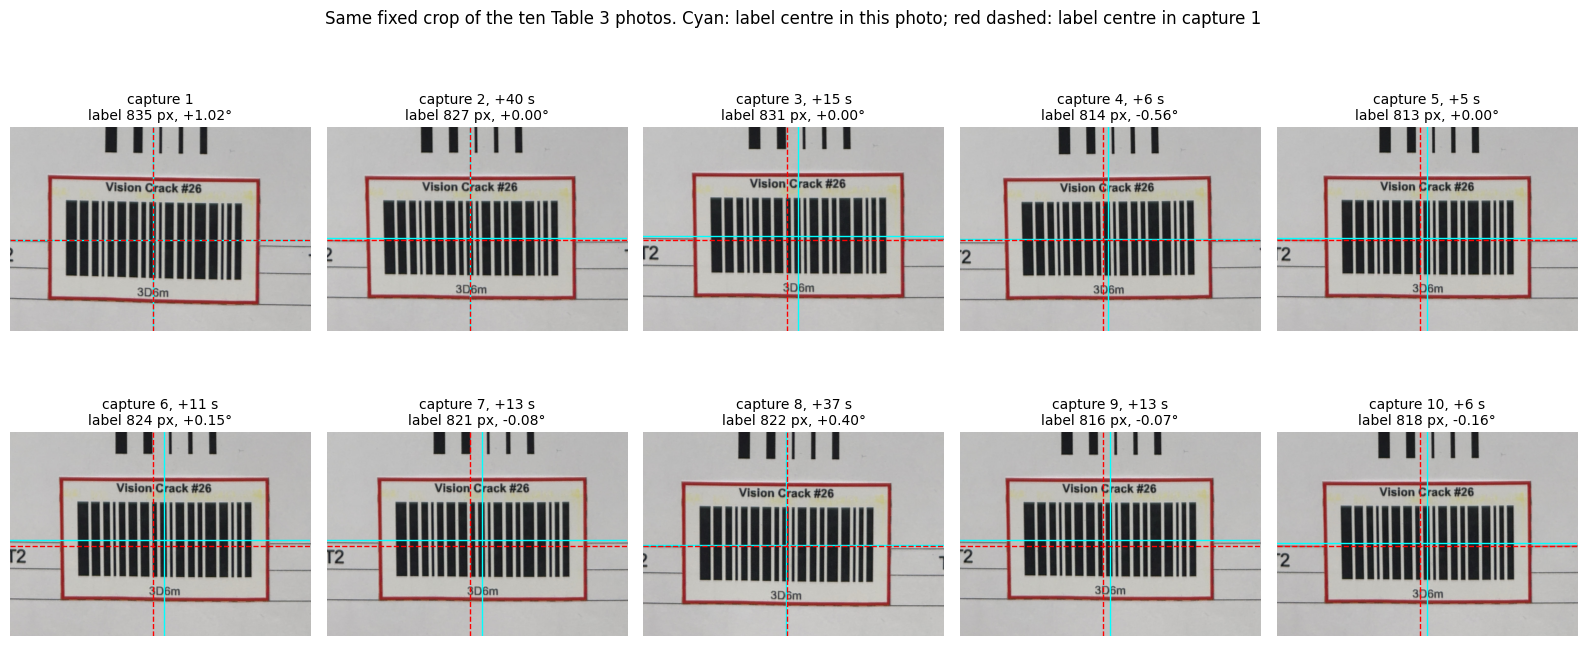

In [ ]:
X0, Y0 = int(RA.label_cx_px.min() - 560), int(RA.label_cy_px.min() - 420)
fig, axes = plt.subplots(2, 5, figsize=(16, 7.4))
for i, (ax, a) in enumerate(zip(axes.ravel(), RA.itertuples())):
    ax.imshow(imgs[i][Y0:Y0 + 800, X0:X0 + 1180])
    ax.axvline(a.label_cx_px - X0, color='cyan', lw=1); ax.axhline(a.label_cy_px - Y0, color='cyan', lw=1)
    ax.axvline(RA.label_cx_px[0] - X0, color='red', lw=1, ls='--'); ax.axhline(RA.label_cy_px[0] - Y0, color='red', lw=1, ls='--')
    dt = '' if np.isnan(a.seconds_after_previous) else f', +{a.seconds_after_previous:.0f} s'
    ax.set_title(f'capture {i + 1}{dt}\nlabel {a.label_width_px:.0f} px, {a.angle_deg:+.2f}°', fontsize=10); ax.axis('off')
fig.suptitle('Same fixed crop of the ten Table 3 photos. Cyan: label centre in this photo; red dashed: label centre in capture 1', fontsize=12)
plt.tight_layout(); plt.savefig(FIG / 'table3_reacquisition.png', dpi=110); plt.show()

## 4 · Ink spread and an independent check of the scale

The 18 barcode bars have known design widths. Fitting measured width (px) against design width (mm) gives a slope (the scale) and
an offset. If the bars were printed exactly at their design width the fit would pass through zero; the offset is the ink spread.

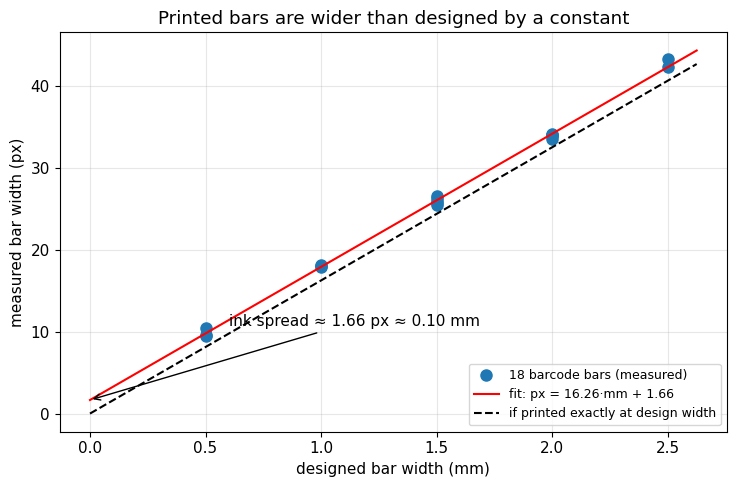

ink spread over the ten photos: 1.64 ± 0.07 px = 0.102 mm
barcode scale 0.0622 mm/px vs. Eq. (13) 50/797 = 0.0627 mm/px (-0.9 %)


In [ ]:
p0 = caps.path.iloc[0]
img = vc.read_rgb(p0); (cx, cy), (w, h), _ = field.find_red_label(img); W, H = max(w, h), min(w, h)
r0 = field.measure_field(p0)
g = field.grey(field.derotate(img, r0.angle_deg, (cx, cy)))
bc = field.read_barcode(g, (int(cx - W / 2), int(cy - H / 2), int(cx + W / 2), int(cy + H / 2)))
mm = np.asarray(BARCODE_CLASS_MM)[np.asarray(encode(bc['code'])) - 1]; px = bc['bars_px']
sl, off = np.polyfit(mm, px, 1)
fig, ax = plt.subplots(figsize=(7.5, 5)); xx = np.linspace(0, mm.max() * 1.05, 50)
ax.plot(mm, px, 'o', ms=8, label='18 barcode bars (measured)')
ax.plot(xx, sl * xx + off, 'r-', label=f'fit: px = {sl:.2f}·mm + {off:.2f}')
ax.plot(xx, sl * xx, 'k--', label='if printed exactly at design width')
ax.annotate(f'ink spread ≈ {off:.2f} px ≈ {off / sl:.2f} mm', xy=(0, off), xytext=(0.6, off + 9), arrowprops=dict(arrowstyle='->'))
ax.set(xlabel='designed bar width (mm)', ylabel='measured bar width (px)', title='Printed bars are wider than designed by a constant')
ax.grid(alpha=.3); ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.savefig(FIG / 'ink_spread.png', dpi=150); plt.show()

ink_mm = (RA.ink_spread_px * RA.scale_barcode)
print(f'ink spread over the ten photos: {RA.ink_spread_px.mean():.2f} ± {RA.ink_spread_px.std():.2f} px = {ink_mm.mean():.3f} mm')
print(f'barcode scale {RA.scale_barcode.mean():.4f} mm/px vs. Eq. (13) 50/797 = {50 / 797:.4f} mm/px '
      f'({100 * (RA.scale_barcode.mean() / (50 / 797) - 1):+.1f} %)')
assert abs(RA.scale_barcode.mean() / (50 / 797) - 1) < 0.02

## 5 · MDC with a 95 % confidence interval

MDC₉₅ = 1.96·√2·σp, with σp the pooled SD of the ten captures over the five targets (5 × 9 = 45 degrees of freedom).
The interval of σp follows from the χ² distribution and carries over to the MDC.

In [ ]:
t1 = pd.read_csv(TAB / 'table1.csv', index_col=0)
v = t1.loc[[f'VisionCrack {i}' for i in range(1, 11)]].astype(float)
ins = t1.loc[[f'Inspector {i}' for i in range(1, 11)]].astype(float)
dfree = 5 * 9
sp = np.sqrt(v.var(ddof=1).mean()); mdc = 1.96 * np.sqrt(2) * sp
lo, hi = mdc * np.sqrt(dfree / chi2.ppf(.975, dfree)), mdc * np.sqrt(dfree / chi2.ppf(.025, dfree))
si = np.sqrt(ins.var(ddof=1).mean())
print(f'VisionCrack (one operator, one session): pooled SD {sp:.4f} mm, MDC {mdc:.3f} mm, 95 % CI {lo:.3f}–{hi:.3f} mm')
print(f'Inspectors (ten readers, one reading each): pooled SD {si:.4f} mm, 1.96·√2·SD {1.96 * np.sqrt(2) * si:.3f} mm')
assert (round(mdc, 3), round(lo, 3), round(hi, 3)) == (0.030, 0.025, 0.037)

VisionCrack (one operator, one session): pooled SD 0.0107 mm, MDC 0.030 mm, 95 % CI 0.025–0.037 mm
Inspectors (ten readers, one reading each): pooled SD 0.1347 mm, 1.96·√2·SD 0.373 mm


## 6 · Identifier decoding

Decode success on every capture we have. The payload of the printed label is checked against the expected code; a misread to a
different valid code would count as a failure.

In [ ]:
dec = sw.assign(condition=sw.file.map(dict(zip(t2.file, t2.folder))).map(NAME))
D = dec.groupby('condition', sort=False).decode_ok.agg(['sum', 'count'])
D.loc['All sensitivity captures'] = D.sum()
D['rate_%'] = 100 * D['sum'] / D['count']
print(D)
print('Table 3 photos decoded:', (RA.code == RA.code.iloc[0]).sum(), '/', len(RA), '→ code', RA.code.iloc[0])
assert D.loc['All sensitivity captures', 'sum'] == 39 and (RA.code == RA.code.iloc[0]).all()

                          sum  count      rate_%
condition                                       
Frontal (same session)      4      4  100.000000
Distance                    6      6  100.000000
In-plane rotation ≈ 15°    12     12  100.000000
Pitch                      11     11  100.000000
Yaw                         6     12   50.000000
All sensitivity captures   39     45   86.666667
Table 3 photos decoded: 10 / 10 → code 3D6m


## 7 · Per-row pixel counts of the Table 3 photos

Every scan line used for Table 3, with the dark-run length in pixels of each of the five printed bars. Rows that do not show exactly
five bars are skipped by the pipeline (Eq. 9); these are the rows that remain. Each bar's width is the clipped mean of its column
(mean ± 1.645 SD), times the scale 50/797 mm/px.

In [ ]:
from visioncrack.constants import ET_LAYOUT
recs = []
for path, bbox in zip(caps.path, caps.bbox):
    m = vc.measure_capture(vc.read_rgb(path), bbox, roi)
    for i, line in enumerate(m.et_M):
        recs.append({'photo': path.name, 'row': i, **{f'ET{cls}_px': int(line[col]) for col, cls in enumerate(ET_LAYOUT)}})
RC = pd.DataFrame(recs)
RC.to_csv(TAB / 'table3_per_row_counts.csv', index=False)
print(len(RC), 'rows over', RC.photo.nunique(), 'photos;', RC.groupby('photo').size().min(), '–', RC.groupby('photo').size().max(), 'rows per photo')
print('ET2 pixel counts over all rows of all photos:', RC.ET2_px.value_counts().to_dict())
RC.head()

2729 rows over 10 photos; 267 – 283 rows per photo
ET2 pixel counts over all rows of all photos: {17: 2388, 16: 255, 18: 86}


,photo,row,ET5_px,ET4_px,ET1_px,ET2_px,ET3_px
0,1752392841.png,0,45,35,10,17,27
1,1752392841.png,1,45,36,10,17,27
2,1752392841.png,2,45,36,10,18,28
3,1752392841.png,3,45,36,10,18,28
4,1752392841.png,4,45,35,10,18,28


**Why SD = 0 at ET2.** The ET2 rows read 16, 17 or 18 px in every photo, so the photos differ row by row. The bar width is the
mean after clipping rows outside mean ± 1.645 SD. At ET2 almost all rows read 17 px, so the clip removes every 16 and 18 and leaves
exactly 17 px (= 1.0665 mm) in all ten photos. Without the clip (plain mean of all rows) ET2 varies between photos and the pooled
SD is almost unchanged.

In [ ]:
from visioncrack.width import clipped_mean
s = 50 / 797; cols = [f'ET{k}_px' for k in range(1, 6)]
clip = RC.groupby('photo')[cols].agg(clipped_mean) * s
plain = RC.groupby('photo')[cols].mean() * s
CMP = pd.DataFrame({'clipped mean (published)': clip.std(ddof=1), 'plain mean of all rows': plain.std(ddof=1)}).T
CMP.columns = [f'SD ET{k}' for k in range(1, 6)]
CMP['pooled SD'] = np.sqrt((CMP ** 2).mean(1))
print('share of ET2 rows reading 16 or 18 px per photo:', (RC.ET2_px != 17).groupby(RC.photo).mean().round(2).tolist())
assert (clip['ET2_px'] / s == 17).all() and plain['ET2_px'].std() > 0
assert round(CMP.loc['clipped mean (published)', 'pooled SD'], 3) == 0.011 and round(CMP.loc['plain mean of all rows', 'pooled SD'], 3) == 0.010
CMP.round(4)

share of ET2 rows reading 16 or 18 px per photo: [0.11, 0.13, 0.17, 0.08, 0.07, 0.16, 0.1, 0.14, 0.19, 0.1]


,SD ET1,SD ET2,SD ET3,SD ET4,SD ET5,pooled SD
clipped mean (published),0.0057,0.0000,0.0131,0.0143,0.0126,0.0107
plain mean of all rows,0.0056,0.0034,0.0109,0.0106,0.0150,0.0100


## Summary

* **Table 2 (one scale, all frames):** frontal captures have the smallest spread under either scale; the app rejects 39 of the 41
  perturbed frames. MAE rankings depend on the scale, so the paper argues from spread and acceptance.
* **Rectification:** on the same ten photos, pooled SD 0.011 → 0.024 mm and MAE 0.061 → 0.075 mm.
* **Re-acquisition:** the label moved and changed size and angle between the ten photos. SD = 0 at ET2 is the outlier clip leaving\n  only 17-px rows in every photo; without the clip ET2 SD is 0.003 mm and the pooled SD 0.010 mm (published 0.011 mm).\n* **Per-row counts:** `table3_per_row_counts.csv`.
* **Ink spread:** printed bars are ≈ 0.1 mm wider than designed; the barcode scale agrees with 50/797 within about 1 %.
* **MDC:** 0.030 mm, 95 % CI 0.025–0.037 mm (within one session).
* **Decoding:** 39 of 45 sensitivity captures and 10 of 10 Table 3 photos.